# 03 · Baseline: logistic regression

**Questions this notebook answers**

1. How well does a simple, interpretable model rank fraud (PR-AUC, with uncertainty)?
2. Does class weighting help it?
3. Which inputs does it lean on?

**Protocol** (fixed in `notes/00_preregistration.md`, amendment A2): dev split only, locked
5-fold CV × 3 repeats = 15 validation folds. One-hot categoricals, `log1p` on amount and balance,
standardised numerics, L2 penalty with `C = 1`. Two pipelines are compared on the same folds with
the corrected resampled t-test; the weighted version replaces the unweighted one only if the 95% CI
of the PR-AUC difference lies entirely above 0.

In [1]:
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e.cv import metric_ci, pick, run_cv, save_result, verdict_text
from fraud_e2e.data import load_raw
from fraud_e2e.features import feature_frame
from fraud_e2e.models import fit_pipeline
from fraud_e2e.reporting import write_json
from fraud_e2e.splits import dev_only

P.set_style()
dev = dev_only(load_raw())
print(f"dev: {len(dev):,} rows, {int(dev[C.TARGET].sum())} fraud")

dev: 16,000 rows, 271 fraud


## 1. Cross-validate both variants

In [2]:
lr = run_cv(dev, {"model": "logreg"}, "logreg")
lr_bal = run_cv(dev, {"model": "logreg", "imbalance": "class_weight"}, "logreg_balanced")
for r in (lr, lr_bal):
    save_result(r)


def table(results):
    rows = []
    for r in results:
        row = {"pipeline": r.name}
        for m in ["pr_auc", "roc_auc", "brier"]:
            ci = metric_ci(r, m)
            row[m] = f"{ci['mean']:.3f} [{ci['ci_low']:.3f}, {ci['ci_high']:.3f}]"
            row[f"{m}_sd"] = round(ci["sd"], 3)
        rows.append(row)
    return pd.DataFrame(rows)


table([lr, lr_bal])

,pipeline,pr_auc,pr_auc_sd,roc_auc,roc_auc_sd,brier,brier_sd
0,logreg,"0.415 [0.341, 0.490]",0.062,"0.942 [0.928, 0.957]",0.012,"0.013 [0.012, 0.013]",0.001
1,logreg_balanced,"0.391 [0.315, 0.467]",0.063,"0.935 [0.919, 0.951]",0.013,"0.089 [0.085, 0.093]",0.004


Values are the mean over 15 folds with a corrected 95% interval. The no-skill PR-AUC equals the
fraud rate of a fold, about 0.017.

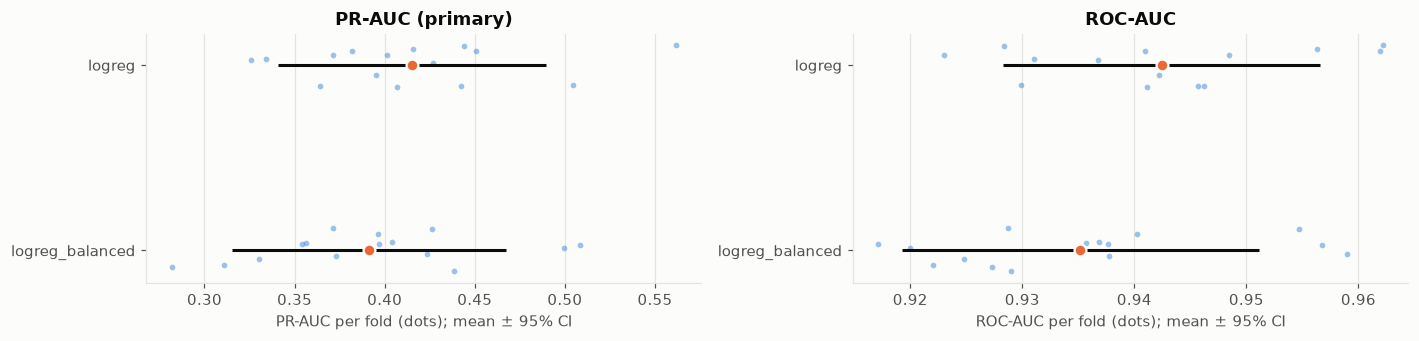

In [3]:
fig, axes = P.plt.subplots(1, 2, figsize=(13, 3.2))
P.fold_dots([lr, lr_bal], "pr_auc", ax=axes[0], xlabel="PR-AUC per fold (dots); mean ± 95% CI")
P.fold_dots([lr, lr_bal], "roc_auc", ax=axes[1], xlabel="ROC-AUC per fold (dots); mean ± 95% CI")
axes[0].set_title("PR-AUC (primary)")
axes[1].set_title("ROC-AUC")
fig.tight_layout()
P.save(fig, "p2_baseline_folds")
P.plt.show()

## 2. Paired comparison (pre-registered rule)

In [4]:
chosen, test_ap = pick(lr, lr_bal, "pr_auc")
_, test_roc = pick(lr, lr_bal, "roc_auc")
_, test_brier = pick(lr, lr_bal, "brier", lower_is_better=True)
cmp = pd.DataFrame([test_ap, test_roc, test_brier])[
    ["metric", "mean_diff_b_minus_a", "ci_low", "ci_high", "p_value", "b_wins_per_folds", "verdict"]
]
cmp

,metric,mean_diff_b_minus_a,ci_low,ci_high,p_value,b_wins_per_folds,verdict
0,pr_auc,-0.023700,-0.046745,-0.000656,4.461284e-02,2,a better
1,roc_auc,-0.007276,-0.013965,-0.000588,3.506005e-02,1,a better
2,brier,0.076445,0.071802,0.081088,4.373127e-15,15,a better


In [5]:
display(
    Markdown(
        f"PR-AUC difference (balanced − unweighted): **{test_ap['mean_diff_b_minus_a']:+.4f}** "
        f"(95% CI {test_ap['ci_low']:+.4f} to {test_ap['ci_high']:+.4f}), balanced better in "
        f"{test_ap['b_wins_per_folds']} of {test_ap['n_folds']} folds → verdict: "
        f"**{verdict_text(test_ap)}**. Baseline carried forward: **`{chosen.name}`**."
    )
)

PR-AUC difference (balanced − unweighted): **-0.0237** (95% CI -0.0467 to -0.0007), balanced better in 2 of 15 folds → verdict: **`logreg` is better**. Baseline carried forward: **`logreg`**.

Class weighting reweights the loss; it is expected to change probabilities (Brier) far more than
ranking (PR-AUC), which is why the decision is made on PR-AUC.

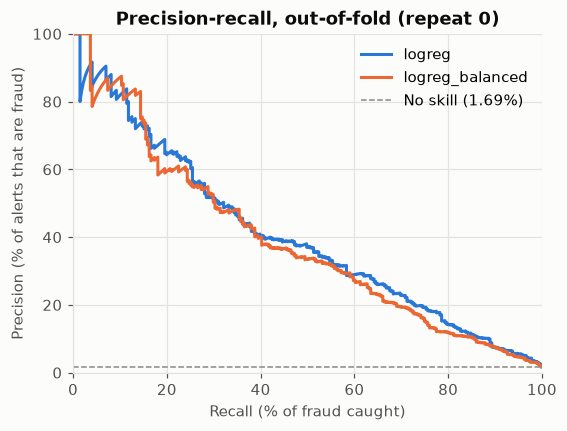

In [6]:
fig, ax = P.plt.subplots(figsize=(5.5, 4))
P.pr_curves([lr, lr_bal], ax=ax)
ax.set_title("Precision-recall, out-of-fold (repeat 0)")
P.save(fig, "p2_baseline_pr")
P.plt.show()

## 3. What the baseline relies on

Coefficients of the chosen variant refit on all dev rows. Inputs are standardised (or 0/1 for
booleans and one-hot levels), so a coefficient is the change in log-odds per standard deviation
(or for the flag/level being present).

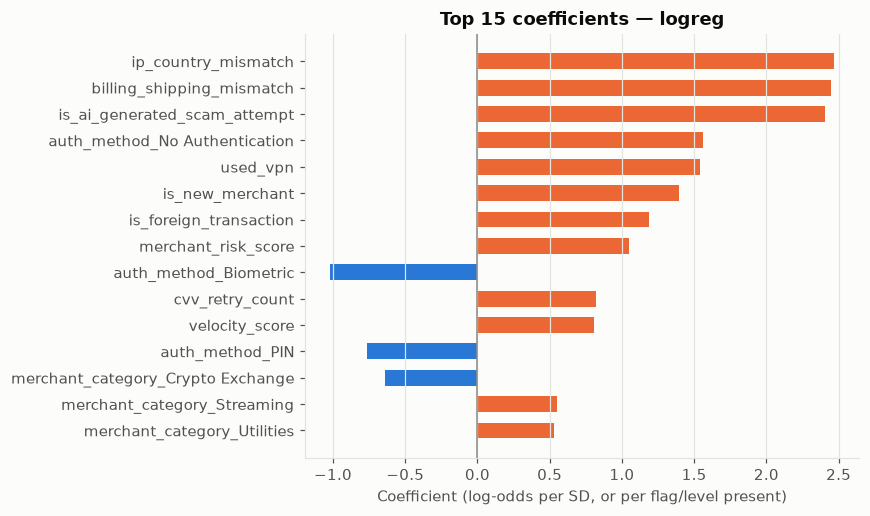

In [7]:
model = fit_pipeline(chosen.spec, feature_frame(dev), dev[C.TARGET].to_numpy())
names = model.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({"input": names, "coef": model.named_steps["model"].coef_[0]})
coef["input"] = coef["input"].str.replace(r"^\w+?__", "", regex=True)
top = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(15)

fig, ax = P.plt.subplots(figsize=(6.5, 5))
t = top.iloc[::-1]
ax.barh(t["input"], t["coef"], color=[P.FRAUD if c > 0 else P.LEGIT for c in t["coef"]], height=0.6)
ax.axvline(0, color=P.NEUTRAL, lw=1)
ax.set_xlabel("Coefficient (log-odds per SD, or per flag/level present)")
ax.set_title(f"Top 15 coefficients — {chosen.name}")
ax.grid(axis="y", visible=False)
P.save(fig, "p2_baseline_coefficients")
P.plt.show()

## 4. Save

In [8]:
saved = write_json(
    {
        "pipelines": {
            r.name: {m: metric_ci(r, m) for m in ["pr_auc", "roc_auc", "brier"]} | {"spec": r.spec}
            for r in (lr, lr_bal)
        },
        "comparisons": [test_ap, test_roc, test_brier],
        "chosen_baseline": chosen.name,
        "top_coefficients": top.to_dict(orient="records"),
    },
    "p2_baseline",
)
print("saved", saved.relative_to(C.ROOT))

saved reports/p2_baseline.json


## Summary

In [9]:
ci = metric_ci(chosen, "pr_auc")
roc = metric_ci(chosen, "roc_auc")
base = chosen.folds["base_rate"].mean()
pos = top[top["coef"] > 0].head(3)["input"].tolist()
display(
    Markdown(f"""
- **Baseline:** `{chosen.name}` — PR-AUC **{ci["mean"]:.3f}** (95% CI {ci["ci_low"]:.3f}–{ci["ci_high"]:.3f},
  fold SD {ci["sd"]:.3f}), about **{ci["mean"] / base:.0f}×** the no-skill value of {base:.3f};
  ROC-AUC {roc["mean"]:.3f} ({roc["ci_low"]:.3f}–{roc["ci_high"]:.3f}).
- **Class weighting:** on PR-AUC, {verdict_text(test_ap)} (difference {test_ap["mean_diff_b_minus_a"]:+.4f},
  CI {test_ap["ci_low"]:+.4f} to {test_ap["ci_high"]:+.4f}), so the rule keeps `{chosen.name}`.
- **Strongest positive drivers:** {", ".join(f"`{p}`" for p in pos)}.
- **Fold-to-fold spread:** the PR-AUC SD across folds ({ci["sd"]:.3f}) is
  {ci["sd"] / abs(test_ap["mean_diff_b_minus_a"]):.1f}× the size of the weighting effect — the
  yardstick for every comparison in notebook 04.
""")
)


- **Baseline:** `logreg` — PR-AUC **0.415** (95% CI 0.341–0.490,
  fold SD 0.062), about **25×** the no-skill value of 0.017;
  ROC-AUC 0.942 (0.928–0.957).
- **Class weighting:** on PR-AUC, `logreg` is better (difference -0.0237,
  CI -0.0467 to -0.0007), so the rule keeps `logreg`.
- **Strongest positive drivers:** `ip_country_mismatch`, `billing_shipping_mismatch`, `is_ai_generated_scam_attempt`.
- **Fold-to-fold spread:** the PR-AUC SD across folds (0.062) is
  2.6× the size of the weighting effect — the
  yardstick for every comparison in notebook 04.
